# Flash drought decomposition reanalysis results

In [1]:
import glob as glob
import xarray as xr
import pandas as pd
import geopandas as gpd
import sys
import os
import numpy as np
import time
import zarr
import matplotlib.pyplot as plt
import gc

In [2]:
sys.path.append('/g/data/mn51/users/jb6465/code/flash-drought/attribution-python')
from attribution import *
from plotting import *
from extract import *

In [3]:
import warnings
import logging
warnings.filterwarnings('ignore') 
logging.getLogger("distributed.worker.memory").setLevel(logging.ERROR)
logging.getLogger("distributed.shuffle._scheduler_plugin").setLevel(logging.ERROR)
logging.getLogger('flox').setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [4]:
import dask
import tempfile
from dask.diagnostics import ProgressBar
from dask.distributed import Client, LocalCluster

dask.config.set({
    # 'array.chunk-size': "256 MiB",
    # 'array.slicing.split_large_chunks': True, #This can make AXIOM very slow
    'distributed.comm.timeouts.connect': '120s',
    'distributed.comm.timeouts.tcp': '120s',
    'distributed.comm.retry.count': 10,
    'distributed.scheduler.allowed-failures': 20,
    "distributed.scheduler.worker-saturation": 1.1, #This should use the new behaviour which helps with memory pile up
})

client = Client(n_workers=10, threads_per_worker=1, local_directory = tempfile.mkdtemp(), memory_limit = "765000mb")
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/8787/status,
Dashboard: /proxy/8787/status,Workers: 10
Total threads: 10,Total memory: 6.96 TiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:33453,Workers: 0
Dashboard: /proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:44561,Total threads: 1
Dashboard: /proxy/41661/status,Memory: 712.46 GiB
Nanny: tcp://127.0.0.1:41531,


In [1]:
short_tall_switch = 'short'

## Ref ET driver sensitivities

##### only need to compute once and save locally

In [6]:
%%time
barra_root_dir = '/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2'
R = xr.open_mfdataset(f'{barra_root_dir}/rsds/*.nc').rsds.chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
T = 0.5*(xr.open_mfdataset(f'{barra_root_dir}/tasmin/*.nc').tasmin+xr.open_mfdataset(f'{barra_root_dir}/tasmax/*.nc').tasmax).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
q = xr.open_mfdataset(f'{barra_root_dir}/huss/*.nc').huss.chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
U = (xr.open_mfdataset(f'{barra_root_dir}/sfcWind/*.nc').sfcWind * (4.87 / np.log(67.8 * 10.0 - 5.42))).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
Patm = xr.open_mfdataset(f'{barra_root_dir}/ps/*.nc').ps.chunk({'time':-1, 'lat':'auto', 'lon':'auto'})

CPU times: user 19.2 s, sys: 6.28 s, total: 25.5 s
Wall time: 53.4 s


compute DOY 7-day smoothed means for sensitivity calculations

In [7]:
R_climo = compute_doy_climo(compute_rolling_xday(R*86400, 7, centre_window=True))
T_climo = compute_doy_climo(compute_rolling_xday(T-273.15, 7, centre_window=True))
q_climo = compute_doy_climo(compute_rolling_xday(q, 7, centre_window=True))
U_climo = compute_doy_climo(compute_rolling_xday(U, 7, centre_window=True))
Patm_climo = compute_doy_climo(compute_rolling_xday(Patm, 7, centre_window=True))

In [8]:
elev = xr.open_dataset(f'/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/fx/orog/v20231001/orog_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1.nc').orog

compute sensitvities and write locally

In [9]:
%%time
sens_T, sens_R, sens_q, sens_U = compute_driver_sensivities(R_climo,T_climo,U_climo,q_climo,Patm_climo,elev,
                                                            short_tall_crop_switch = short_tall_switch)

CPU times: user 1min 10s, sys: 15.8 s, total: 1min 26s
Wall time: 2min 50s


In [10]:
%%time
save_dir = f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/driver_sensitivities"
sensitivity_key = ['sens_T', 'sens_R', 'sens_q', 'sens_U']
units = ['(mm/day)/(K)', '(mm/day)/(W/m2)', '(mm/day)/(kg/kg)', '(mm/day)/(m/s)']

for i, driver_sensitivity in enumerate([sens_T, sens_R, sens_q, sens_U]):
    start = time.time()
    saver = xr.Dataset({f"{sensitivity_key[i]}": driver_sensitivity.assign_attrs(long_name=f"{sensitivity_key[i][-1]} driver sensitvity", units=str(units[i]))}).reset_coords(drop=True).astype('float32').to_zarr(f"{save_dir}/{sensitivity_key[i]}.zarr", mode="w", consolidated=True, encoding={f"{sensitivity_key[i]}": {"compressor": zarr.Blosc(cname='zstd', clevel=5, shuffle=1)}})
    end = time.time()
    print(f"~ {sensitivity_key[i][-1]} driver sensitivity computed in {end - start:.2f} s")

~ T driver sensitivity computed in 694.53 s
~ R driver sensitivity computed in 499.28 s
~ q driver sensitivity computed in 500.75 s
~ U driver sensitivity computed in 635.55 s
CPU times: user 17min 34s, sys: 2min 2s, total: 19min 36s
Wall time: 38min 50s


##### plotting

In [54]:
sens_T = xr.open_dataset(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/driver_sensitivities/sens_T.zarr").sens_T
sens_R = xr.open_dataset(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/driver_sensitivities/sens_R.zarr").sens_R
sens_q = xr.open_dataset(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/driver_sensitivities/sens_q.zarr").sens_q
sens_U = xr.open_dataset(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/driver_sensitivities/sens_U.zarr").sens_U

In [55]:
idx = lambda m: pd.Timestamp(f"2001-{m}-01").dayofyear - 1
print(idx("May"))
print(idx("Nov"))

120
304


In [56]:
%%time
MJASSO_sens_T = mask_ocean(sens_T.isel(doy=slice(120, 304)).mean(dim="doy"))
MJASSO_sens_R = mask_ocean(sens_R.isel(doy=slice(120, 304)).mean(dim="doy"))
MJASSO_sens_q = mask_ocean(sens_q.isel(doy=slice(120, 304)).mean(dim="doy"))
MJASSO_sens_U = mask_ocean(sens_U.isel(doy=slice(120, 304)).mean(dim="doy"))

NDJFMA_sens_T = mask_ocean(xr.concat([sens_T.isel(doy=slice(304,None)), sens_T.isel(doy=slice(0,120))], "doy").mean("doy"))
NDJFMA_sens_R = mask_ocean(xr.concat([sens_R.isel(doy=slice(304,None)), sens_R.isel(doy=slice(0,120))], "doy").mean("doy"))
NDJFMA_sens_q = mask_ocean(xr.concat([sens_q.isel(doy=slice(304,None)), sens_q.isel(doy=slice(0,120))], "doy").mean("doy"))
NDJFMA_sens_U = mask_ocean(xr.concat([sens_U.isel(doy=slice(304,None)), sens_U.isel(doy=slice(0,120))], "doy").mean("doy"))


CPU times: user 58.1 s, sys: 18.7 s, total: 1min 16s
Wall time: 2min 13s


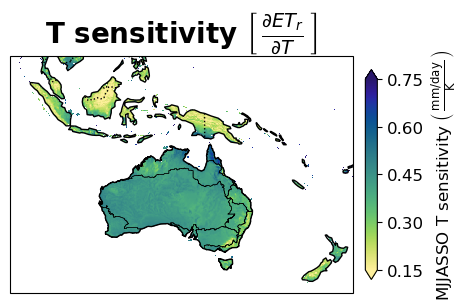

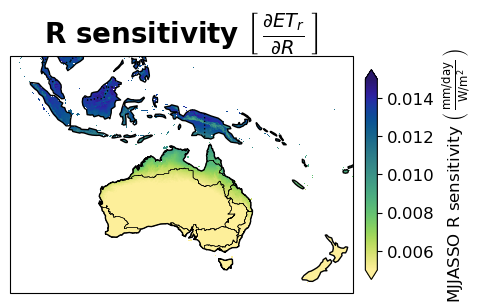

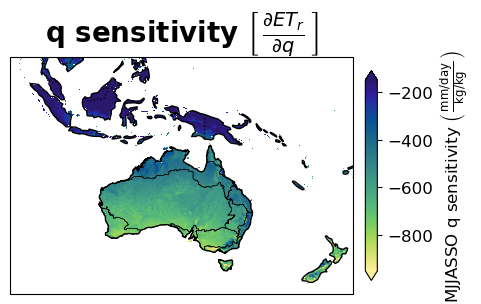

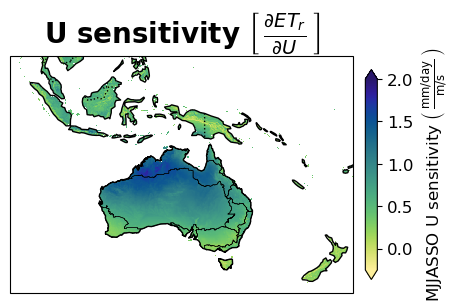

In [57]:
import cmocean
plot_titles = ["T sensitivity " + r"$\left[\,\frac{\partial ET_r}{\partial T}\,\right]$",
              "R sensitivity " + r"$\left[\,\frac{\partial ET_r}{\partial R}\,\right]$",
              "q sensitivity " + r"$\left[\,\frac{\partial ET_r}{\partial q}\,\right]$",
              "U sensitivity " + r"$\left[\,\frac{\partial ET_r}{\partial U}\,\right]$"]

units = ["MJJASSO T sensitivity " + r"$\left(\,\frac{\mathrm{mm/day}}{\mathrm{K}}\,\right)$",
        "MJJASSO R sensitivity " + r"$\left(\,\frac{\mathrm{mm/day}}{\mathrm{W/m^2}}\,\right)$",
        "MJJASSO q sensitivity " + r"$\left(\,\frac{\mathrm{mm/day}}{\mathrm{kg/kg}}\,\right)$",
        "MJJASSO U sensitivity " + r"$\left(\,\frac{\mathrm{mm/day}}{\mathrm{m/s}}\,\right)$"]

maxs = [0.75, 0.015, -150, 2]
mins = [0.15, 0.005, -950, -0.25 ]
for plot_idx, plot_array in enumerate([MJASSO_sens_T, MJASSO_sens_R, MJASSO_sens_q, MJASSO_sens_U]):
    create_multiplot(nrows=1, ncols=1, plot_fontsize=12, title_size=20, figsize=(4, 6), plot_extent=[90, 180, -40, 9], plot_marker=None,
        plot_list=[[plot_array]],
        shapefile = 'NRM',
        shapefile_linewidth = 0.4,
        col_titles=[plot_titles[plot_idx]],
        col_titles_all_rows_switch=False,
        cmap_list=[cmocean.cm.haline_r],
        cbar_labels=[units[plot_idx]],
        cbar_extensions=['both'],
        cbar_width = 0.03,
        cbar_height = 0.35,
        cbar_nticks = [5],
        cbar_tick_labels = None,
        cbar_x_y_loc = (0.93, 0.65/2),
        cbar_mins=[mins[plot_idx]],
        cbar_maxs=[maxs[plot_idx]])

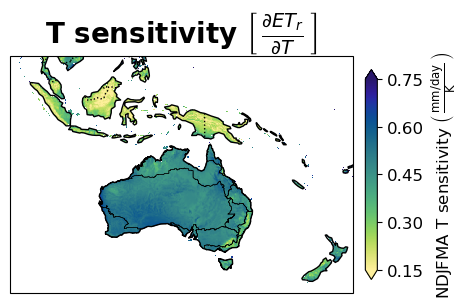

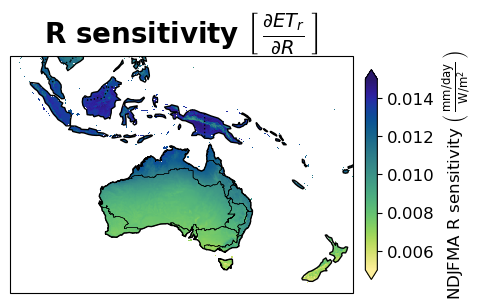

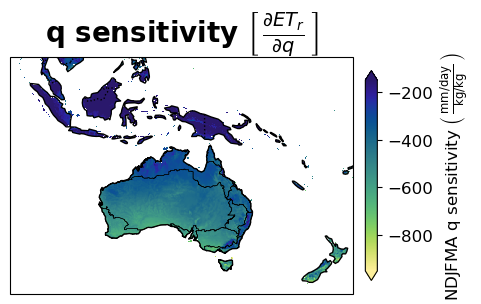

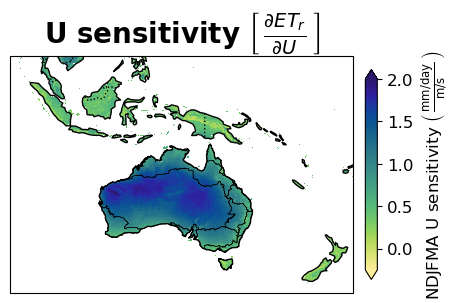

In [58]:
import cmocean
plot_titles = ["T sensitivity " + r"$\left[\,\frac{\partial ET_r}{\partial T}\,\right]$",
              "R sensitivity " + r"$\left[\,\frac{\partial ET_r}{\partial R}\,\right]$",
              "q sensitivity " + r"$\left[\,\frac{\partial ET_r}{\partial q}\,\right]$",
              "U sensitivity " + r"$\left[\,\frac{\partial ET_r}{\partial U}\,\right]$"]

units = ["NDJFMA T sensitivity " + r"$\left(\,\frac{\mathrm{mm/day}}{\mathrm{K}}\,\right)$",
        "NDJFMA R sensitivity " + r"$\left(\,\frac{\mathrm{mm/day}}{\mathrm{W/m^2}}\,\right)$",
        "NDJFMA q sensitivity " + r"$\left(\,\frac{\mathrm{mm/day}}{\mathrm{kg/kg}}\,\right)$",
        "NDJFMA U sensitivity " + r"$\left(\,\frac{\mathrm{mm/day}}{\mathrm{m/s}}\,\right)$"]

maxs = [0.75, 0.015, -150, 2]
mins = [0.15, 0.005, -950, -0.25 ]
for plot_idx, plot_array in enumerate([NDJFMA_sens_T, NDJFMA_sens_R, NDJFMA_sens_q, NDJFMA_sens_U]):
    create_multiplot(nrows=1, ncols=1, plot_fontsize=12, title_size=20, figsize=(4, 6), plot_extent=[90, 180, -40, 9], plot_marker=None,
        plot_list=[[plot_array]],
        shapefile = 'NRM',
        shapefile_linewidth = 0.4,
        col_titles=[plot_titles[plot_idx]],
        col_titles_all_rows_switch=False,
        cmap_list=[cmocean.cm.haline_r],
        cbar_labels=[units[plot_idx]],
        cbar_extensions=['both'],
        cbar_width = 0.03,
        cbar_height = 0.35,
        cbar_nticks = [5],
        cbar_tick_labels = None,
        cbar_x_y_loc = (0.93, 0.65/2),
        cbar_mins=[mins[plot_idx]],
        cbar_maxs=[maxs[plot_idx]])

## $ET_0$ driver contributions

In [24]:
barra_root_dir = '/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2'

ET0 = xr.open_mfdataset(f'{barra_root_dir}/RefET/ETr/*.nc').ETr_tall_crop.chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
R = xr.open_mfdataset(f'{barra_root_dir}/rsds/*.nc').rsds.chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
T = 0.5*(xr.open_mfdataset(f'{barra_root_dir}/tasmin/*.nc').tasmin+xr.open_mfdataset(f'{barra_root_dir}/tasmax/*.nc').tasmax).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
q = xr.open_mfdataset(f'{barra_root_dir}/huss/*.nc').huss.chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
U = (xr.open_mfdataset(f'{barra_root_dir}/sfcWind/*.nc').sfcWind * (4.87 / np.log(67.8 * 10.0 - 5.42))).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})

In [25]:
ET0_anom = compute_daily_anom(compute_rolling_xday(ET0, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
T_anom = compute_daily_anom(compute_rolling_xday(T, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
R_anom = compute_daily_anom(compute_rolling_xday(R, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
q_anom = compute_daily_anom(compute_rolling_xday(q, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
U_anom = compute_daily_anom(compute_rolling_xday(U, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})

In [28]:
%%time
T_cont = (T_anom*sens_T.sel(doy=T_anom['time'].dt.dayofyear)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
R_cont = (R_anom*sens_R.sel(doy=R_anom['time'].dt.dayofyear)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
q_cont = (q_anom*sens_q.sel(doy=q_anom['time'].dt.dayofyear)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
U_cont = (U_anom*sens_U.sel(doy=U_anom['time'].dt.dayofyear)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})

CPU times: user 13min 36s, sys: 2min 29s, total: 16min 5s
Wall time: 13min 45s


In [9]:
%%time
save_dir = f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/driver_contributions"
contribution_key = ['cont_T', 'cont_R', 'cont_q', 'cont_U']

for i, driver_contribution in enumerate([T_cont, R_cont, q_cont, U_cont]):
    start = time.time()
    driver_contribution = driver_contribution.reset_coords(drop=True)
    saver = xr.Dataset({f"{contribution_key[i]}": driver_contribution.assign_attrs(long_name=f"{contribution_key[i][-1]} driver contribution", units="mm")}).reset_coords(drop=True).astype('float32').to_zarr(f"{save_dir}/{contribution_key[i]}.zarr", mode="w", consolidated=True, encoding={f"{contribution_key[i]}": {"compressor": zarr.Blosc(cname='zstd', clevel=5, shuffle=1)}})
    end = time.time()
    print(f"~ {contribution_key[i][-1]} driver contribution computed in {end - start:.2f} s")

~ T driver contribution computed in 548.40 s
~ R driver contribution computed in 505.79 s
~ q driver contribution computed in 497.32 s
~ U driver contribution computed in 527.45 s
CPU times: user 14min 47s, sys: 5min 52s, total: 20min 40s
Wall time: 34min 38s


In [10]:
T_cont = xr.open_dataset(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/driver_contributions/cont_T.zarr").cont_T.chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
R_cont = xr.open_dataset(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/driver_contributions/cont_R.zarr").cont_R.chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
q_cont = xr.open_dataset(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/driver_contributions/cont_q.zarr").cont_q.chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
U_cont = xr.open_dataset(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/driver_contributions/cont_U.zarr").cont_U.chunk({'time':-1, 'lat':'auto', 'lon':'auto'})

In [11]:
total = T_cont + R_cont+ q_cont + U_cont
total_safe = total.where((total < -0.1) | (total > 0.1), np.nan)

In [12]:
rel_T_cont = (T_cont/total_safe)
rel_R_cont = (R_cont/total_safe)
rel_q_cont = (q_cont/total_safe)
rel_U_cont = (U_cont/total_safe)

In [13]:
%%time
rel_T_cont_s = rel_T_cont.resample(time="QS-DEC").sum().groupby("time.season").mean("time", skipna=True).compute()
rel_R_cont_s = rel_R_cont.resample(time="QS-DEC").sum().groupby("time.season").mean("time", skipna=True).compute() 
rel_q_cont_s = rel_q_cont.resample(time="QS-DEC").sum().groupby("time.season").mean("time", skipna=True).compute() 
rel_U_cont_s = rel_U_cont.resample(time="QS-DEC").sum().groupby("time.season").mean("time", skipna=True).compute() 

CPU times: user 2min 16s, sys: 21.2 s, total: 2min 37s
Wall time: 12min 58s


In [14]:
rel_T_cont_s = mask_ocean(rel_T_cont_s)
rel_R_cont_s = mask_ocean(rel_R_cont_s)
rel_q_cont_s = mask_ocean(rel_q_cont_s)
rel_U_cont_s = mask_ocean(rel_U_cont_s)

In [15]:
from scipy.stats import rankdata

drivers = [rel_T_cont_s, rel_R_cont_s, q_cont, U_cont]
names = ['T', 'R', 'q', 'U']

stacked = xr.concat(drivers, dim='driver', coords='minimal', compat='override').assign_coords(driver=names)

ranked = xr.DataArray(rankdata(-stacked, axis=0), dims=stacked.dims, coords=stacked.coords)
ranked_drivers = {n: ranked.sel(driver=n) for n in names}

dominant_driver = ranked.idxmin(dim='driver')
driver_map = {'T': 1, 'R': 2, 'q': 3, 'U': 4}

dominant_driver_num = xr.DataArray(np.vectorize(driver_map.get)(dominant_driver.values), dims=dominant_driver.dims, coords=dominant_driver.coords)


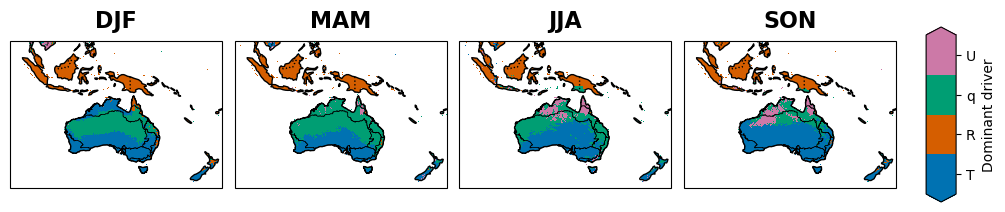

In [35]:
import cmocean
create_multiplot(nrows=1, ncols=4, plot_fontsize=10, title_size=16, figsize=(10, 5), plot_extent=[90, 180, -40, 9], plot_marker=None,
        plot_list=[[dominant_driver_num.astype('float').sel(season='DJF'), 
                    dominant_driver_num.astype('float').sel(season='MAM'), 
                    dominant_driver_num.astype('float').sel(season='JJA'),
                    dominant_driver_num.astype('float').sel(season='SON')]],
        shapefile = 'NRM',
        shapefile_linewidth = 0.4,
        col_titles=['DJF', 'MAM', 'JJA', 'SON'],
        col_titles_all_rows_switch=False,
        cmap_list=[colors.ListedColormap(['#0072B2','#D55E00','#009E73','#CC79A7'])],
        cbar_labels=['Dominant driver'],
        cbar_extensions=['both'],
        cbar_width = 0.03,
        cbar_height = 0.35,
        cbar_nticks = [4],
        cbar_tick_labels = ['-', 'T','R','q','U',],
        cbar_x_y_loc = (0.93, 0.65/2),
        cbar_mins=[0.5],
        cbar_maxs=[4.5])

In [39]:
second_driver = ranked.where(ranked == 2).idxmin(dim='driver')
second_driver_num = xr.DataArray(np.vectorize(driver_map.get)(second_driver.values), dims=second_driver.dims, coords=second_driver.coords)

third_driver = ranked.where(ranked == 3).idxmin(dim='driver')
third_driver_num = xr.DataArray(np.vectorize(driver_map.get)(third_driver.values), dims=third_driver.dims, coords=third_driver.coords)

fourth_driver = ranked.where(ranked == 4).idxmin(dim='driver')
fourth_driver_num = xr.DataArray(np.vectorize(driver_map.get)(fourth_driver.values), dims=fourth_driver.dims, coords=fourth_driver.coords)

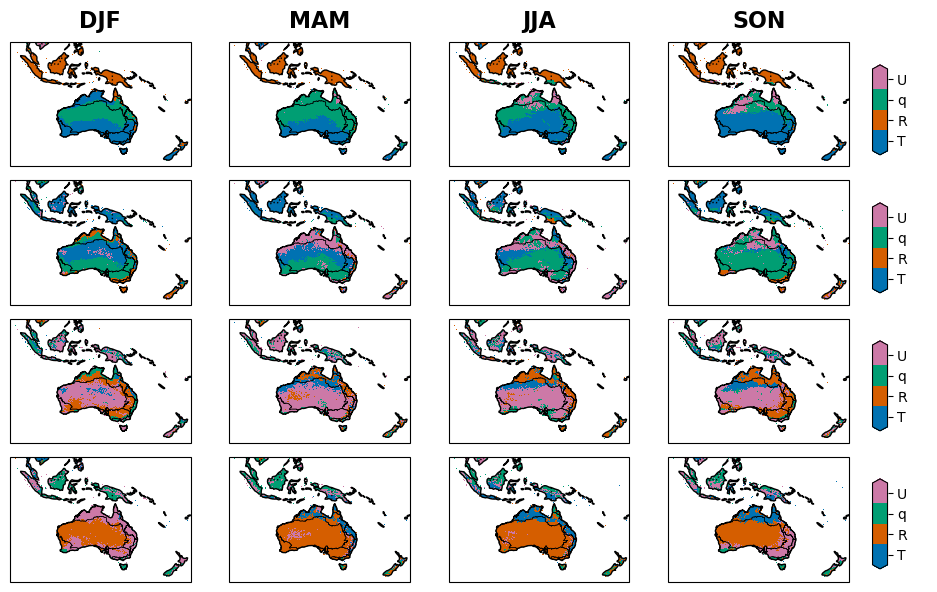

In [58]:
import cmocean
create_multiplot(nrows=4, ncols=4, plot_fontsize=10, title_size=16, figsize=(10, 6), plot_extent=[90, 180, -40, 9], plot_marker=None,
        plot_list=[[dominant_driver_num.astype('float').sel(season='DJF'), 
                    dominant_driver_num.astype('float').sel(season='MAM'), 
                    dominant_driver_num.astype('float').sel(season='JJA'),
                    dominant_driver_num.astype('float').sel(season='SON')],
                  [second_driver_num.astype('float').sel(season='DJF'), 
                    second_driver_num.astype('float').sel(season='MAM'), 
                    second_driver_num.astype('float').sel(season='JJA'),
                    second_driver_num.astype('float').sel(season='SON')],
                  [third_driver_num.astype('float').sel(season='DJF'), 
                    third_driver_num.astype('float').sel(season='MAM'), 
                    third_driver_num.astype('float').sel(season='JJA'),
                    third_driver_num.astype('float').sel(season='SON')],
                  [fourth_driver_num.astype('float').sel(season='DJF'), 
                    fourth_driver_num.astype('float').sel(season='MAM'), 
                    fourth_driver_num.astype('float').sel(season='JJA'),
                    fourth_driver_num.astype('float').sel(season='SON')]],
        shapefile = 'NRM',
        shapefile_linewidth = 0.4,
        col_titles=['DJF', 'MAM', 'JJA', 'SON'],
        col_titles_all_rows_switch=False,
        cmap_list=[colors.ListedColormap(['#0072B2','#D55E00','#009E73','#CC79A7']), colors.ListedColormap(['#0072B2','#D55E00','#009E73','#CC79A7']), colors.ListedColormap(['#0072B2','#D55E00','#009E73','#CC79A7']), colors.ListedColormap(['#0072B2','#D55E00','#009E73','#CC79A7'])],
        cbar_labels=[' ', '', '', ' '],
        cbar_extensions=['both', 'both', 'both', 'both'],
        cbar_width = 0.015,
        cbar_height = 0.15,
        cbar_nticks = [4,4,4,4],
        cbar_tick_labels = ['-', 'T','R','q','U',],
        cbar_x_y_loc = (0.9, 0.045, 0.23),
        cbar_mins=[0.5, 0.5, 0.5, 0.5],
        cbar_maxs=[4.5, 4.5, 4.5, 4.5])

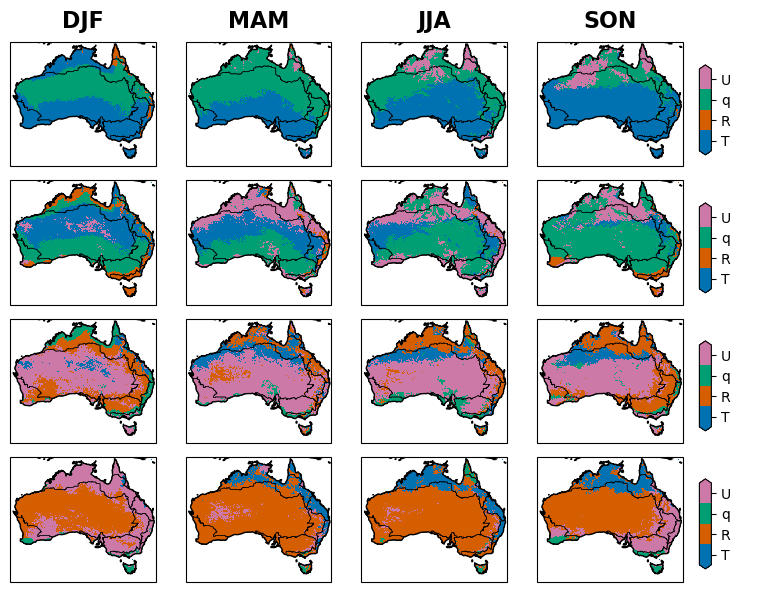

In [60]:
import cmocean
create_multiplot(nrows=4, ncols=4, plot_fontsize=10, title_size=16, figsize=(8, 6), plot_extent=[112, 154, -44, -10], plot_marker=None,
        plot_list=[[dominant_driver_num.astype('float').sel(season='DJF'), 
                    dominant_driver_num.astype('float').sel(season='MAM'), 
                    dominant_driver_num.astype('float').sel(season='JJA'),
                    dominant_driver_num.astype('float').sel(season='SON')],
                  [second_driver_num.astype('float').sel(season='DJF'), 
                    second_driver_num.astype('float').sel(season='MAM'), 
                    second_driver_num.astype('float').sel(season='JJA'),
                    second_driver_num.astype('float').sel(season='SON')],
                  [third_driver_num.astype('float').sel(season='DJF'), 
                    third_driver_num.astype('float').sel(season='MAM'), 
                    third_driver_num.astype('float').sel(season='JJA'),
                    third_driver_num.astype('float').sel(season='SON')],
                  [fourth_driver_num.astype('float').sel(season='DJF'), 
                    fourth_driver_num.astype('float').sel(season='MAM'), 
                    fourth_driver_num.astype('float').sel(season='JJA'),
                    fourth_driver_num.astype('float').sel(season='SON')]],
        shapefile = 'NRM',
        shapefile_linewidth = 0.4,
        col_titles=['DJF', 'MAM', 'JJA', 'SON'],
        col_titles_all_rows_switch=False,
        cmap_list=[colors.ListedColormap(['#0072B2','#D55E00','#009E73','#CC79A7']), colors.ListedColormap(['#0072B2','#D55E00','#009E73','#CC79A7']), colors.ListedColormap(['#0072B2','#D55E00','#009E73','#CC79A7']), colors.ListedColormap(['#0072B2','#D55E00','#009E73','#CC79A7'])],
        cbar_labels=[' ', '', '', ' '],
        cbar_extensions=['both', 'both', 'both', 'both'],
        cbar_width = 0.015,
        cbar_height = 0.15,
        cbar_nticks = [4,4,4,4],
        cbar_tick_labels = ['-', 'T','R','q','U',],
        cbar_x_y_loc = (0.9, 0.045, 0.23),
        cbar_mins=[0.5, 0.5, 0.5, 0.5],
        cbar_maxs=[4.5, 4.5, 4.5, 4.5])

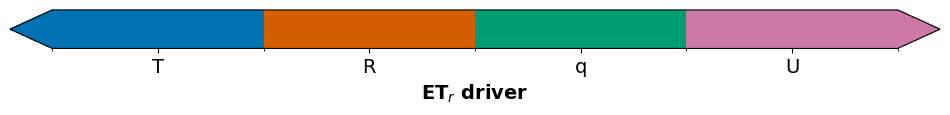

In [11]:
plt.rcParams.update({'font.size': 14})
cmap = colors.ListedColormap(['#0072B2','#D55E00','#009E73','#CC79A7'])
norm = colors.BoundaryNorm(np.arange(0.5, 5.5, 1), cmap.N)

fig, ax = plt.subplots(figsize=(12, 0.5))
cb = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap),
                  cax=ax, orientation='horizontal', extend='both')

cb.set_ticks([1,2,3,4])
cb.set_ticklabels(['T','R','q','U'])
cb.set_label('ET$_r$ driver' if short_tall_switch == 'tall' else 'ET$_0$ driver', fontweight='bold')

plt.show()

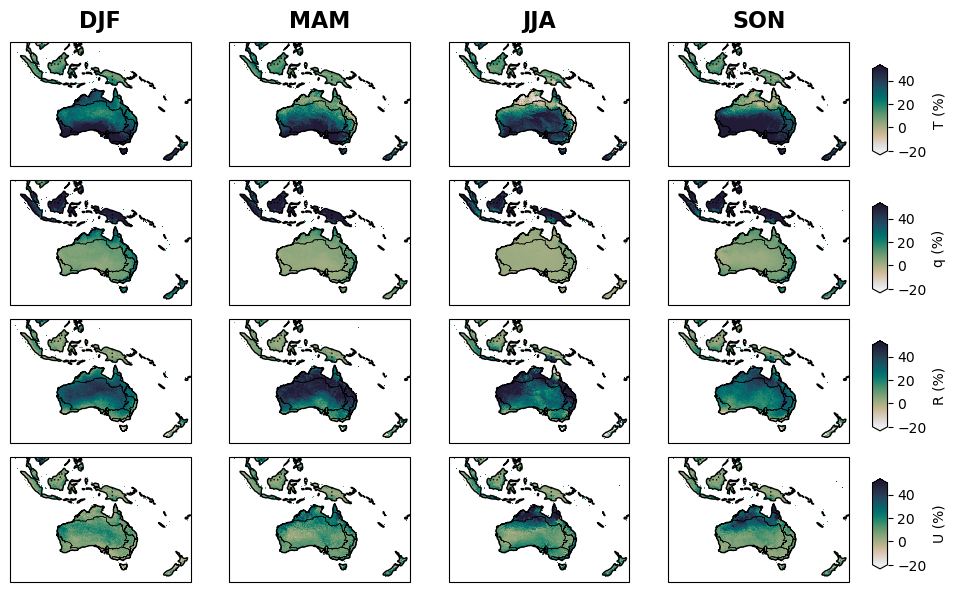

In [58]:
import cmocean
create_multiplot(nrows=4, ncols=4, plot_fontsize=10, title_size=16, figsize=(10, 6), plot_extent=[90, 180, -40, 9], plot_marker=None,
        plot_list=[[rel_T_cont_s.sel(season='DJF'), rel_T_cont_s.sel(season='MAM'), rel_T_cont_s.sel(season='JJA'), rel_T_cont_s.sel(season='SON')],
                  [rel_R_cont_s.sel(season='DJF'), rel_R_cont_s.sel(season='MAM'), rel_R_cont_s.sel(season='JJA'), rel_R_cont_s.sel(season='SON')],
                  [rel_q_cont_s.sel(season='DJF'), rel_q_cont_s.sel(season='MAM'), rel_q_cont_s.sel(season='JJA'), rel_q_cont_s.sel(season='SON')],
                  [rel_U_cont_s.sel(season='DJF'), rel_U_cont_s.sel(season='MAM'), rel_U_cont_s.sel(season='JJA'), rel_U_cont_s.sel(season='SON')]],
        shapefile = 'NRM',
        shapefile_linewidth = 0.4,
        col_titles=['DJF', 'MAM', 'JJA', 'SON'],
        col_titles_all_rows_switch=False,
        cmap_list=[cmocean.cm.rain, cmocean.cm.rain, cmocean.cm.rain, cmocean.cm.rain],
        cbar_labels=['T (%)', 'q (%)', 'R (%)', 'U (%)'],
        cbar_extensions=['both', 'both', 'both', 'both'],
        cbar_width = 0.015,
        cbar_height = 0.15,
        cbar_nticks = [4,4,4,4],
        cbar_tick_labels = None,
        cbar_x_y_loc = (0.9, 0.045, 0.23),
        cbar_mins=[-20, -20, -20, -20],
        cbar_maxs=[50, 50, 50, 50])

# Compute anoms

In [62]:
barra_root_dir = '/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2'
ET = xr.open_mfdataset(f'{barra_root_dir}/RefET/ETr/*.nc').ETr_tall_crop.chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
R = xr.open_mfdataset(f'{barra_root_dir}/rsds/*.nc').rsds.chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
T = 0.5*(xr.open_mfdataset(f'{barra_root_dir}/tasmin/*.nc').tasmin+xr.open_mfdataset(f'{barra_root_dir}/tasmax/*.nc').tasmax).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
q = xr.open_mfdataset(f'{barra_root_dir}/huss/*.nc').huss.chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
U = (xr.open_mfdataset(f'{barra_root_dir}/sfcWind/*.nc').sfcWind * (4.87 / np.log(67.8 * 10.0 - 5.42))).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})

In [ ]:
%%time
# compute rolling day anomalies
ET_anom = compute_daily_anom(compute_rolling_xday(ET, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})#.compute()
T_anom = compute_daily_anom(compute_rolling_xday(T, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})#.compute()
R_anom = compute_daily_anom(compute_rolling_xday(R, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})#.compute()
q_anom = compute_daily_anom(compute_rolling_xday(q, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})#.compute()
U_anom = compute_daily_anom(compute_rolling_xday(U, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})#.compute()

In [32]:
%%time
save_dir = '/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/anoms'
anom_key = ['anom_ETr', 'anom_T', 'anom_R', 'anom_q', 'anom_U']

for i, driver_anom in enumerate([ET0_anom, T_anom, R_anom, q_anom, U_anom]):
    start = time.time()
    driver_anom = driver_anom.reset_coords(drop=True)
    saver = xr.Dataset({f"{anom_key[i]}": driver_anom.assign_attrs(long_name=f"{anom_key[i].split('_')[-1]} driver anom", units="mm")}).reset_coords(drop=True).astype('float32').to_zarr(f"{save_dir}/{anom_key[i]}.zarr", mode="w", consolidated=True, encoding={f"{anom_key[i]}": {"compressor": zarr.Blosc(cname='zstd', clevel=5, shuffle=1)}})
    end = time.time()
    print(f"~ {anom_key[i].split('_')[-1]} anom computed in {end - start:.2f} s")

~ ET0 driver anom computed in 231.77 s
~ T driver anom computed in 325.14 s
~ R driver anom computed in 355.86 s
~ q driver anom computed in 335.06 s
~ U driver anom computed in 329.57 s
CPU times: user 13min 1s, sys: 1min 11s, total: 14min 12s
Wall time: 26min 17s
